<a href="https://colab.research.google.com/github/ArthurLopes985/InteligenciaArtificial_atividades/blob/main/Compara%C3%A7%C3%A3o_AutoML_ArthurLopesOliveira_BrunoSilvaNegy_6D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Imports

In [ ]:
!pip install flaml[automl] -q

Instalando o flaml

In [ ]:
!apt-get install build_essential swig python-3-dev -y
!pip install auto_sklearn2

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
E: Unable to locate package build_essential
E: Unable to locate package python-3-dev


Instalando o auto_sklearn, aqui usamos um fork do GitHub mantido pela comunidade chamado auto_sklearn2 porque o auto_sklearn original não é mais atualizado e está incompativel com a versão python do Colab. Essa versão 2 é atualizada regurlamente e ainda possui compatibilidade.

In [ ]:
from sklearn.preprocessing import StandardScaler
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as skl
import seaborn as sb
import numpy as np
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.datasets import load_iris
from flaml import AutoML
from auto_sklearn2 import AutoSklearnClassifier
import time

Importando todas as biliotecas que serão necessarias

# 2. Carregando o dataset

In [ ]:
iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target, name="species_id")

species_names = {i: name for i, name in enumerate(iris.target_names)}

df = X.copy()
df["species_id"] = y
df["species"] = df["species_id"].map(species_names)



Carregando o dataset iris em um dataframe criado com Pandas.

# 3. Iniciando visualizações

## 3.1 Head

In [ ]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species_id,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


verificando as 5 primeiras linhas para verificar se todas colunas vieram corretamente.

## 3.2 Shape

In [ ]:
df.shape

(150, 6)

verificando quantas linhas e colunas tem.

## 3.3 Describe

In [ ]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species_id
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


Verificando uma descrição das linhas e colunas.

## 3.4 Verificando se tem nulos

In [ ]:
df.isnull().sum()

,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
species_id,0
species,0


Verificando se tem nulos.

# 4. Graficos para visualização

##4.1 Gráfico Histograma

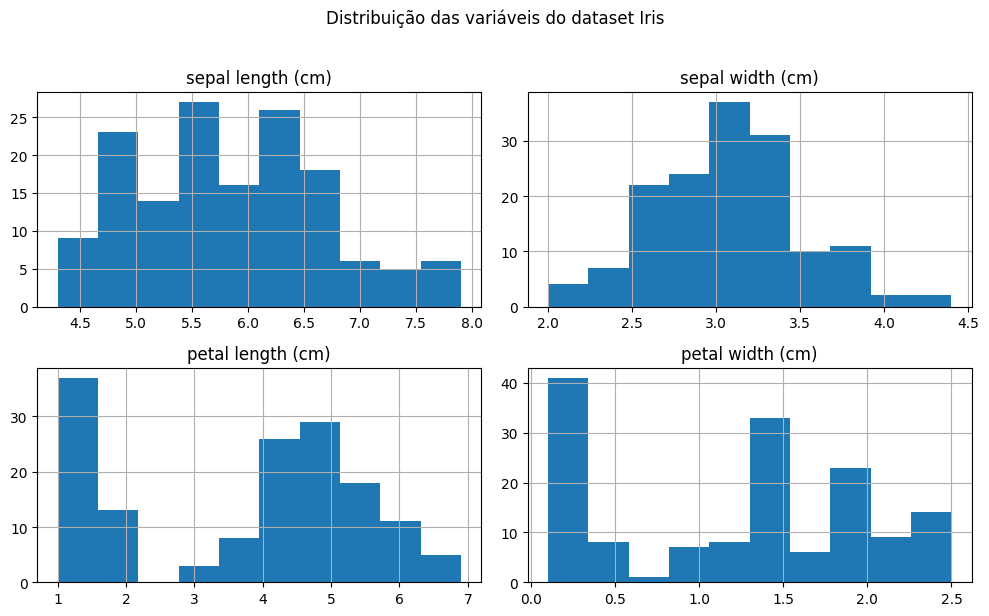

In [ ]:
df[X.columns].hist(figsize=(10, 6))
plt.suptitle("Distribuição das variáveis do dataset Iris", y=1.02)
plt.tight_layout()
plt.show()

Verificando as ocorrencias em cada coluna.

##4.2 Grafico de dispersão

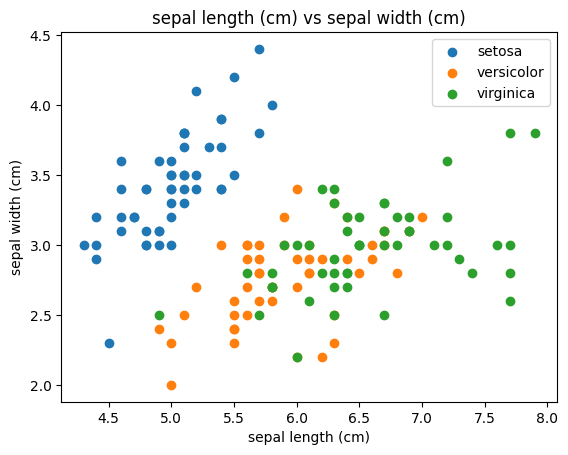

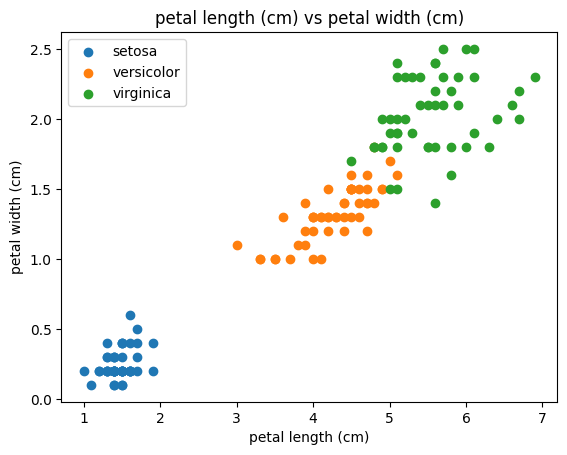

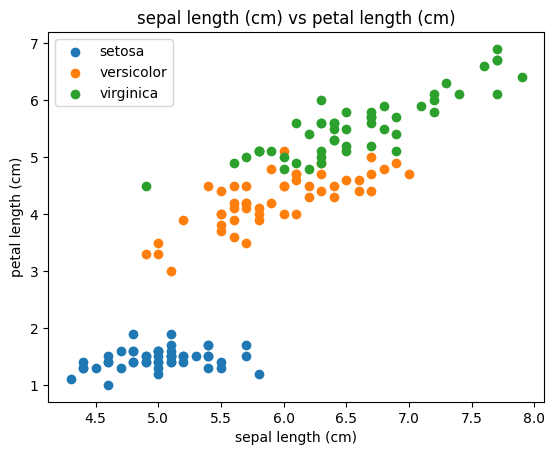

In [ ]:
pairs = [
    ("sepal length (cm)", "sepal width (cm)"),
    ("petal length (cm)", "petal width (cm)"),
    ("sepal length (cm)", "petal length (cm)")
]

for xcol, ycol in pairs:
    plt.figure()
    for species in df["species"].unique():
        subset = df[df["species"] == species]
        plt.scatter(subset[xcol], subset[ycol], label=species)
    plt.xlabel(xcol)
    plt.ylabel(ycol)
    plt.title(f"{xcol} vs {ycol}")
    plt.legend()
    plt.show()

Fazendo comparações entre tamanhoos de petalas, sepalas, etc. para verificar se ocorre uma separação clara,

#5. Separando X e Y

In [ ]:
X = df.drop(columns =["species", "species_id"])
y=df['species']

seprando x(caracteristicas das flores) e y(nome das flores)

#6. Fazendo o treino e o teste

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    random_state=42,
    stratify=y,
    test_size=0.2
)

print("Treino e teste de X: ", X_train.shape, X_test.shape)
print("Treino e teste de y: ", y_train.shape, y_test.shape)

Treino e teste de X:  (120, 4) (30, 4)
Treino e teste de y:  (120,) (30,)


separando 80% para treino e 20% para teste.

#7. Fazendo o StandardScaler

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

padronizando os dados.

#8. Testando o AutoML com flaml

In [ ]:
automl = AutoML()

inilizalizando o modelo autoMl do flaml em uma variavel.

In [ ]:
settings = {
    "time_budget": 30,
    "metric": 'accuracy',
    "task": 'classification',
    'log_file_name': 'flaml.log',
    'verbose': 0
}

Passando as configurações da busca pelo melhor modelo, como tempo, metrica, operação, etc.

In [ ]:
inicio = time.perf_counter()

In [ ]:
print("Iniciando busca pelo melhor modelo com AutoML")
automl.fit(X_train=X_train, y_train=y_train, **settings)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

Iniciando busca pelo melhor modelo com AutoML


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

Treinando o melhor modelo encontrado anteriormente com x e y treino.

In [ ]:
tempo_flaml = time.perf_counter()-inicio
print(f'Tempo de execuçãp FLAML: {tempo_flaml:.2f} segundos')

Tempo de execuçãp FLAML: 30.02 segundos


aqui estamos vendo quanto tempo durou a execução do flaml

In [ ]:
print("Resultados")
print(f'Melhor algoritmo encontrado: {automl.best_estimator}')
print(f"Melhor acuracia: {1- automl.best_loss:.4f}")
print("Acuracia FLAML:", accuracy_score(y_test, y_pred))

Resultados
Melhor algoritmo encontrado: lgbm
Melhor acuracia: 0.9667
Acuracia FLAML: 1.0


printando o melhor algoritmo e a melhor acuracia.

In [ ]:
y_pred = automl.predict(X_test)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


prevendo os dados passando o teste.

#9. Classification report

In [ ]:
print("A classification report do modelo em AutoML com flaml é: ")
print(classification_report(y_test, y_pred))

A classification report do modelo em AutoML com flaml é: 
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



Criando a classificação, passando metricas como precisão, recall, score do f1 e support, para verificar o quão bom foi o modelo identificado.




#10. Matrix de confusão do Flaml

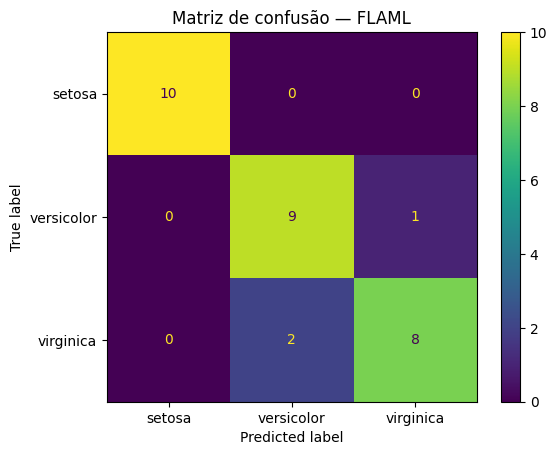

In [ ]:
cm_FLAML = confusion_matrix(y_test, y_pred, labels=iris.target_names)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_FLAML, display_labels=iris.target_names)
disp.plot()
plt.title("Matriz de confusão — FLAML")
plt.show()

Também verificando a qualidade do modelo, fazendo a matriz de confusão, é possivel ver que acertaram todas as previsões, indicando 100%.

#11. Testando AutoML com Auto_Sklearn

In [ ]:
automl2 = AutoSklearnClassifier(
    time_limit=30,
    random_state=42
)

criando o modelo em uma varaivel e passando algumas configurações como tempo limite, nesse caso foi passando 30s. como no anterior do flaml.

# 12. Treinando o Modelo

In [ ]:
inicioautosk = time.perf_counter()
automl2.fit(X_train, y_train)

ERROR:auto_sklearn2:Error evaluating standard_scaler + multinomial_nb: 
All the 5 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/pipeline.py", line 662, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"])
    ~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/l

AutoSklearnClassifier(random_state=42, time_limit=30)

Treinando o modelo passsando x e y treino.

In [ ]:
tempo_autosk = time.perf_counter()-inicioautosk
print(f'Tempo de execuçãp FLAML: {tempo_autosk:.2f} seguundos')

Tempo de execuçãp FLAML: 14.44 seguundos


Verificando quanto tempo durou a execução do autosklearn.

#13. Prevendo

In [ ]:
predictions = automl2.predict(X_test)
print("Acuracia Final? ", accuracy_score(y_test, predictions))
print(automl2.get_models_performance())

Acuracia Final?  1.0
{'standard_scaler_random_forest': np.float64(0.95), 'standard_scaler_gradient_boosting': np.float64(0.95), 'standard_scaler_logistic_regression': np.float64(0.9583333333333334), 'standard_scaler_svc': np.float64(0.9666666666666668), 'standard_scaler_knn': np.float64(0.9583333333333334), 'standard_scaler_mlp': np.float64(0.95), 'standard_scaler_decision_tree': np.float64(0.95), 'standard_scaler_ada_boost': np.float64(0.9333333333333333), 'standard_scaler_extra_trees': np.float64(0.95), 'standard_scaler_bagging': np.float64(0.95), 'standard_scaler_sgd': np.float64(0.9416666666666667), 'standard_scaler_linear_svc': np.float64(0.9416666666666668), 'standard_scaler_gaussian_nb': np.float64(0.95), 'standard_scaler_bernoulli_nb': np.float64(0.7666666666666667), 'standard_scaler_qda': np.float64(0.9666666666666668), 'standard_scaler_lda': np.float64(0.975), 'minmax_scaler_random_forest': np.float64(0.95), 'minmax_scaler_gradient_boosting': np.float64(0.95), 'minmax_scaler_

aqui foi feita a previsão passando x teste, em seguida já foi comparado com y_teste para calcular a acuracia e também foi pritando as performances dos modelos.

#14. Classification Report

In [ ]:
print("A classification report do modelo em AutoML com AutoSklearn é: ")
print(classification_report(y_test, predictions))

A classification report do modelo em AutoML com AutoSklearn é: 
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



Criando a classificação, passando metricas como precisão, recall, score do f1 e support, para verificar o quão bom foi o modelo identificado.


#15. Matriz de Confusão

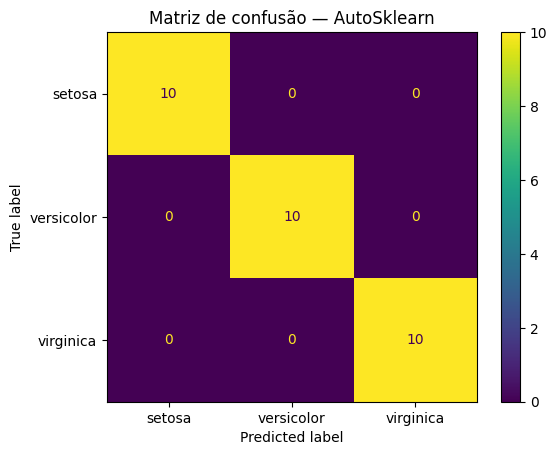

In [ ]:
cm_autosklearn = confusion_matrix(y_test, predictions, labels=iris.target_names)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_autosklearn, display_labels=iris.target_names)
disp.plot()
plt.title("Matriz de confusão — AutoSklearn")
plt.show()

Também verificando a qualidade do modelo, fazendo a matriz de confusão, é possivel ver que acertaram todas as previsões, indicando 100%.

# 16. Conclusão

Em relação ao desempenho, ambos os frameworks obtiveram resultados iguais, alcançando 100% de acurácia no conjunto de teste do Iris. Portanto, houve empate entre as ferramentas, demonstrando que tanto o FLAML quanto o Auto-Sklearn conseguiram classificar corretamente todas as amostras avaliadas. O FLAML selecionou o algoritmo LightGBM (LGBM), enquanto o Auto-Sklearn apresentou uma combinação de modelos, incluindo Robust Scaler com LDA, MinMax Scaler com QDA e Standard Scaler com LDA.

Quanto ao custo computacional, o FLAML apresentou um tempo de execução de 30,02 segundos, enquanto o Auto-Sklearn concluiu sua execução em 14,44 segundos, sendo aproximadamente duas vezes mais rápido neste experimento. Apesar da diferença de tempo, ambos conseguiram atingir o mesmo desempenho. Em relação à inspeção dos modelos, o FLAML facilitou a identificação do melhor algoritmo individual por meio da indicação direta do modelo selecionado. Já o Auto-Sklearn permitiu observar diferentes combinações de algoritmos e técnicas de pré-processamento, proporcionando uma visão mais ampla dos pipelines utilizados e do ensemble gerado.